# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 5. Нейронные сети.


**Правила, <font color="red">прочитайте внимательно</font>:**

1. Общее

     * Выполненную работу **в формате `ipynb`** нужно отправить по ссылке "Сдача ДЗ" на <a href="https://thetahat.ru/courses/ad"><b>странице курса</b></a>. **Работы, присланные иным способом, не принимаются.** Дедлайны указаны в боте и на сайте, они являются строгими.
     
     * Обязательно изучите <a href="https://thetahat.ru/courses/design-hw"><b>руководство по оформлению ДЗ</b></a>. В частности, оно содержит примеры случаев, когда могут быть снижены баллы.
     
     * Обратите внимание на <a href="https://thetahat.ru/courses/ai-rules"><b>правила использования ИИ-инструментов</b></a> при решении домашнего задания.
     
     * Выполнять задание необходимо полностью самостоятельно. **При обнаружении списывания (в т.ч. злоупотребление ИИ) всем участникам списывания дается штраф -3 скор-балла к итоговой оценке.**
     
     * Решение теоретических задач оформляйте в markdown-ячейках формате $\LaTeX$. При решении можно использовать ИИ-инструменты только для оформления написанного самостоятельно решения. Например, написать черновик формул и попросить ИИ оформить эти формулы в $\LaTeX$.
     
      * Решение проверяется системой ИИ-проверки <a href="https://thetahat.ru/thetagrader"><img src="https://miptstats.github.io/theta_grader_small.png" style="display: inline; vertical-align: middle;"> **ThetaGrader**</a>. Результат проверки валидируется и исправляется человеком, после чего комментарии отправляются студентам.
     </br>

2. Правила заполнения ноутбука

     * Запрещается удалять имеющиеся в ноутбуке ячейки, менять местами положения существующих ячеек.
     * Отвечайте на вопросы, а также добавляйте новые ячейки в любом количестве в предложенных местах, которые обозначены `<...>`.
     * Сохраняйте естественный линейный порядок повествования в ноутбуке сверху-вниз. Комментарии к решению пишите в markdown-ячейках.
     * Условия <font color="red"><b>запрещается модифицировать</b></font>.
     * При нарушении данных правил работа может получить 0 баллов.
</br>


**Баллы за задание**

* Задача 1 &mdash; 60 баллов;
* Задача 2 &mdash; 60 баллов;
* Задача 3 &mdash; 70 баллов.

In [245]:
# Bot check

# HW_ID: fpmi_ad5
# Бот проверит этот ID и предупредит, если случайно сдать что-то не то.

# Status: final
# Перед отправкой в финальном решении удали "not" в строчке выше.
# Так бот проверит, что ты отправляешь финальную версию, а не промежуточную.
# Никакие значения в этой ячейке не влияют на факт сдачи работы.

In [3]:
from typing import Tuple
import time

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import clear_output
from torchvision import transforms
from torchvision.datasets import MNIST
from IPython.display import SVG, display

sns.set_theme(palette="Set2", font_scale=1.2)

torch.manual_seed(26)
np.random.seed(26)

### Ссылки на использование ИИ

Если при решении задач использовался ИИ, укажи здесь публичные ссылки на все чаты с ИИ и поясни, для каких целей он применялся. Обрати внимание на <a href="https://thetahat.ru/courses/ai-rules" target="_top">правила</a>.

**Задача 1, 3**
1. https://chat.deepseek.com/share/dkbemoqlw32zawztxc
    - в основном разбирала то, что было на лекции; спрашивала, что делает тот или иной метод и синтаксис; смотрела примеры; разобрала ошибку с индексами во 2 задании


### 📌 Примечание

В ходе доработки решения были внесены следующие исправления:

**Задача 2, Пункт 1:**
- Добавлены размерности входов и выходов в виде таблицы (сразу под схемой)
- Ранее была схема, нарисованная от руки. Она заменена на более читабельную версию с добавлением размерностей прямо на схеме (кроме добавления размерностей ничего не менялось)

**Задача 2, Пункт 2:**
- Добавлен явный вывод производной функции потерь по выходу сети: $\frac{\partial \mathscr{L}_i}{\partial \hat y_i} = \frac{\hat y_i - y_i}{\hat y_i(1-\hat y_i)}$
- Производная сигмоиды выражена через саму функцию сигмоиды: $\frac{\partial \hat y_i}{\partial s_i} = \hat y_i(1-\hat y_i)$

**Задача 3, Пункт 1:**
- Явно указано, что сложность вычисления градиента по весам первого слоя линейно зависит от числа слоёв сети: $O(L)$

---

### Задача 1.

Обратимся вновь к уже знакомому нам по первому занятию датасету **MNIST**. Как вы помните, этот набор данных содержит изображения рукописных цифр, каждое из которых имеет размер **28x28**. Всего в датасете содержится **60 000** изображений в обучающей выборке и еще **10 000** — в тестовой.

В этой домашней работе мы немного упростим данные, а именно:
* сожмем изображения в два раза по каждой из размерностей, то есть до **14x14**,
* оставим **10 000** изображений в обучающей выборке.

> *Примечание.* При желании вы можете усложнить данные &mdash; отказаться от сжатия изображений и/или увеличить количество данных. Однако учтите, что в таком случае модели будут работать дольше, и, возможно, вам будет сложнее достичь желаемых результатов.

**Наша задача остается прежней:** *по изображению определить, какая цифра на нем нарисована.*
На этот раз мы будем решать ее с помощью простых нейронных сетей. Также мы заглянем "под капот" нейросетей, чтобы лучше понять процесс их обучения.

> *Примечание.* Обычно подобные задачи, связанные с изображениями, решаются с помощью сверточных нейронных сетей, которые лучше подходят для работы с изображениями. Они станут темой наших следующих занятий, ждем всех!

Ниже представлена готовая функция для загрузки и предварительной обработки данных.
В рамках этой функции мы выполняем следующие шаги.
* Загрузка исходных данных.
* Сохранение **10 000** изображений в качестве обучающей выборки.
* Сжатие изображений в два раза по каждой из осей, что приводит к размеру **14x14**..
* Растягиваем изображение размером **14x14** в вектор длиной $14 \cdot 14 = 196$. Более подробно эта операция описана на первом занятии.

In [247]:
def load_mnist(
    train_size: int = 10_000, target_size: int = 14
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Загружает и подготавливает данные MNIST для обучения и тестирования.

    Параметры:
    train_size (int): Количество обучаемых данных. По умолчанию 6000.
    target_size (int): Размер, до которого уменьшаются изображения. По умолчанию 14.

    Возвращает:
    train_images (torch.Tensor): Тензор с изображениями для обучения.
    train_labels (torch.Tensor): Тензор с метками для обучения.
    test_images (torch.Tensor): Тензор с изображениями для тестирования.
    test_labels (torch.Tensor): Тензор с метками для тестирования.

    Данные загружаются из набора MNIST, нормализуются, уменьшаются в
    размере и преобразуются в векторы. Для обучения используется только
    часть (train_fraction) от исходного набора данных.
    """

    PIXEL_MAX_VALUE = 255.0  # Для нормализации значений пикселей

    # Создаем преобразование для данных: конвертируем изображения в тензоры PyTorch
    transform = transforms.Compose(
        [
            # Преобразует изображение в тензор и нормализует значения в диапазоне [0, 1]
            transforms.ToTensor(),
        ]
    )

    # Загружаем обучающий и тестовый наборы данных MNIST
    train_dataset = MNIST(root="./data", train=True, transform=transform, download=True)
    test_dataset = MNIST(root="./data", train=False, transform=transform, download=True)

    # Выбираем часть обучающего набора данных
    train_indices = np.random.choice(len(train_dataset), train_size, replace=False)

    # Преобразуем изображения в тензоры и нормализуем их, деля на PIXEL_MAX_VALUE
    train_images = train_dataset.data[train_indices].unsqueeze(1).float() / PIXEL_MAX_VALUE
    test_images = test_dataset.data.unsqueeze(1).float() / PIXEL_MAX_VALUE

    # Уменьшаем размер изображений до target_size x target_size с использованием билинейной интерполяции
    train_images = torch.nn.functional.interpolate(
        train_images, size=(target_size, target_size), mode="bilinear", align_corners=False
    )
    test_images = torch.nn.functional.interpolate(
        test_images, size=(target_size, target_size), mode="bilinear", align_corners=False
    )

    # Преобразуем изображения в векторы (разворачиваем в одномерные массивы)
    train_images = train_images.view(train_size, -1)
    test_images = test_images.view(len(test_dataset), -1)

    # Получаем метки для выбранных обучающих и всех тестовых данных
    train_labels = train_dataset.targets[train_indices]
    test_labels = test_dataset.targets

    return train_images, train_labels, test_images, test_labels

Загрузим данные и посмотрим на их размерности

In [248]:
train_images, train_labels, test_images, test_labels = load_mnist()

print("Train:", train_images.shape, train_labels.shape)
print("Test:", test_images.shape, test_labels.shape)

Train: torch.Size([10000, 196]) torch.Size([10000])
Test: torch.Size([10000, 196]) torch.Size([10000])



**1.** Используя `Sequential` подход в PyTorch, напишите модель нейронной сети по следующему описанию.

* **Вход**: изображение в виде вектора.
* **Два линейных слоя** с промежуточной размерностью 64.
* **Функция активации**: между линейными слоями используется `ReLU`, а на выходе второго слоя — отсутствует (или используется тождественная функция).
* **Выход**: вектор логитов размером 10, соответствующий количеству классов.

> Эта нейронная сеть для изображения $x$ оценивает вектор логитов $\left(\ell_0(x),..., \ell_9(x)\right)$ принадлежности к каждому из классов, аналогично логистической регрессии. Имея оценку логитов $\left(\ell_0(x),..., \ell_9(x)\right)$ , можно получить оценку вероятности $p_k$ для каждого класса по следующей формуле, используя softmax-функцию (обобщение логистической сигмоиды)
> $$
\widehat{p}_k(x) = \frac{\exp\left(\widehat{\ell}_k(x)\right)}{\exp\left(\widehat{\ell}_0(x)\right) +... + \exp\left(\widehat{\ell}_9(x)\right)},
$$
> которая реализуется с помощью функции `nn.functional.softmax(..., dim=-1)`. В качестве оценки класса можно взять класс с наибольшей вероятностью, что можно реализовать с помощью метода `argmax(axis=...)` у тензора в PyTorch.

In [249]:
model = nn.Sequential(
    # Вход: вектор длины 196; выход: 64
    nn.Linear(14 * 14, 64),
    nn.ReLU(),
    # Вход: 64 (берёт выход от первого слоя); выход: 10
    nn.Linear(64, 10)
)

model

Sequential(
  (0): Linear(in_features=196, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=10, bias=True)
)

In [250]:
# Функция для оценки качества модели
def accuracy_from_logits(logits, y_true):
    preds = logits.argmax(dim=1)
    return (preds == y_true).float().mean().item()


**2.** **Напишите цикл обучения нейросети**, используя кросс-энтропию `nn.CrossEntropyLoss()` качестве лосс-функции. Это обобщение бинарной кросс-энтропии, которую мы рассматривали на лекции по логистической регрессии. Ее реализация в PyTorch принимает на вход логиты (что и возвращает наша нейросеть) и истинные метки классов. Обучайте сеть на полном наборе данных с помощью метода градиентного спуска `torch.optim.SGD`, не разбивая данные на случайные батчи (как это делается в SGD).


Примерно каждые 5-10 итераций выполняйте следующие действия:

* Получите текущие предсказания классов для обучающей и тестовой выборок.
* Посчитайте точность (accuracy) классификации для этих выборок.
* Постройте график зависимости точности классификации от номера итерации (от начала обучения до текущей итерации) для обучающей и тестовой выборок. Перед построением графика используйте `clear_output(wait=True)` для плавной очистки холста в процессе обновления графика. Посмотрите примеры в ноутбуке с занятия.
* Сохраните следующие значения:
    * Значение лосс-функции.
    * Точность классификации для обучающей и тестовой выборок.
    * Матрицы весов для каждого слоя.

*Замечания:*
* Рекомендуем сохранять данные в заранее подготовленный словарь, ключи которого соответствуют именам переменных (например, `"weights_layer_2"`), а значения словаря представляют собой списки значений этих переменных по итерациям.
* При сохранении не забывайте вызывать метод `.detach().numpy()` для преобразования матриц в массивы numpy. Также может потребоваться заново инициализировать матрицы с помощью `np.array(...)`, чтобы сохранить сами матрицы, а не ссылки на них, по которым значения меняются в процессе обучения сети.

Выполните 10 000 итераций обучения. Сколько времени это заняло?

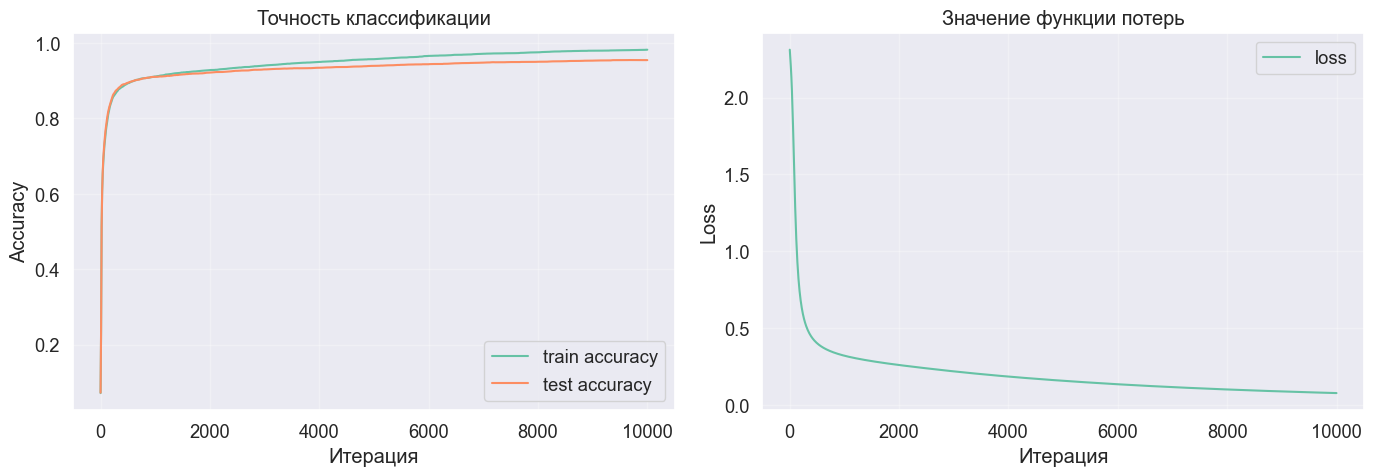

Итерация: 10000
Loss: 0.0765
Train accuracy: 0.9815
Test accuracy: 0.9539
Время обучения: 154.52 сек (2.58 мин)
Финальная точность на тесте: 0.9539


In [251]:
# Настройка обучения
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

num_iters = 10_000
log_every = 10
save_iters = [1, 10, 50, 100, 500, 1000, 2000, 5000, 8000, 10000]  # точки для сохранения весов

# Списки для графиков
loss_values = []
train_accuracy = []
test_accuracy = []
iterations = []

# Для весов используем словарь словарей
weights_history = {
    "layer_1": {},  # ключ — итерация, значение — матрица весов
    "layer_2": {},
}

start_time = time.time()

for iteration in range(1, num_iters + 1):
    # Прямой проход, считаем loss, обратный проход
    optimizer.zero_grad()

    train_logits = model(train_images)
    loss = loss_fn(train_logits, train_labels)

    loss.backward()
    optimizer.step()

    # Сохраняем веса в нужные моменты
    if iteration in save_iters:
        weights_history["layer_1"][iteration] = model[0].weight.detach().numpy().copy()
        weights_history["layer_2"][iteration] = model[2].weight.detach().numpy().copy()

    # Логируем метрики
    if iteration % log_every == 0 or iteration == 1:
        # Оцениваем на train и test
        with torch.no_grad():  # отключаем вычисление градиентов на этом этапе
            train_logits = model(train_images)
            test_logits = model(test_images)

            train_acc = accuracy_from_logits(train_logits, train_labels)
            test_acc = accuracy_from_logits(test_logits, test_labels)

        # Сохраняем в историю
        loss_values.append(loss.item())
        train_accuracy.append(train_acc)
        test_accuracy.append(test_acc)
        iterations.append(iteration)

        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # График точности
        axes[0].plot(iterations, train_accuracy, label="train accuracy")
        axes[0].plot(iterations, test_accuracy, label="test accuracy")
        axes[0].set_title("Точность классификации")
        axes[0].set_xlabel("Итерация")
        axes[0].set_ylabel("Accuracy")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        # График потерь
        axes[1].plot(iterations, loss_values, label="loss")
        axes[1].set_title("Значение функции потерь")
        axes[1].set_xlabel("Итерация")
        axes[1].set_ylabel("Loss")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        print(f"Итерация: {iteration}")
        print(f"Loss: {loss.item():.4f}")
        print(f"Train accuracy: {train_acc:.4f}")
        print(f"Test accuracy: {test_acc:.4f}")

elapsed_time = time.time() - start_time

print(f"Время обучения: {elapsed_time:.2f} сек ({elapsed_time / 60:.2f} мин)")
print(f'Финальная точность на тесте: {test_accuracy[-1]:.4f}')

### Ответ:
Нейросеть была обучена с помощью функции потерь CrossEntropyLoss, которая принимает на вход логиты модели и истинные метки классов.
Оптимизация выполнялась методом градиентного спуска torch.optim.SGD на полном наборе обучающих данных без разбиения на батчи.

В ходе обучения росла точность классификации как на обучающей, так и на тестовой выборке, а значение функции потерь уменьшалось.
По итогам 10 000 итераций обучения были получены следующие результаты:

- Финальное значение функции потерь: 0.0765

- Точность на обучающей выборке: 98.15%

- Точность на тестовой выборке: 95.39%

Итоговая точность на тестовой выборке составила 95.39%, что подтверждает корректность обучения.

Обучение заняло примерно 154.52 сек (2.58 мин).

Проверьте себя, точность классификации на тестовой выборке должна быть около $90\%$. Если вы получили значительно меньший результат (менее $85\%$), попробуйте явно инициализировать веса сети и настроить разные значения `learning_rate` для разных параметров (посмотрите примеры с занятия). Если эти меры не помогут, то стоит поискать ошибку. Да, обучение нейронных сетей — это непростой процесс.

In [252]:
print(f'Финальная точность на тесте: {test_accuracy[-1]:.4f}')

Финальная точность на тесте: 0.9539



**3.** Теперь самое интересное &mdash; заглянем под капот нашей нейросети!

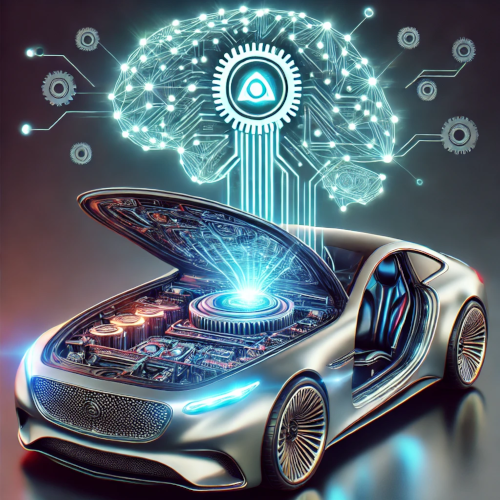

Для более глубокого понимания работы нейросети **визуализируем матрицы весов** для нескольких итераций обучения. Тем самым, вы сможете оценить, как меняется поведение модели в процессе обучения.

1. Выберите примерно 10 итераций обучения, включая первую и последнюю.
2. Для каждого слоя настройте график, используя предоставленный шаблон.

Обратите внимание, что для корректной визуализации матрицы весов ее необходимо **транспонировать**. Например, для первого слоя вертикальная ось должна соответствовать входу сети, а горизонтальная — промежуточной размерности.

В качестве цветовой палитры выбрана `"bwr"`, что позволяет отображать положительные числа матрицы красным цветом, а отрицательные — синим. Чтобы достичь этого, также **необходимо установить параметры `vmin` и `vmax`** симметрично относительно нуля, чтобы нули отображались белым цветом. Подберите эти значения таким образом, чтобы получить наиболее четкую картинку, на которой выделяются определенные группы пикселей.

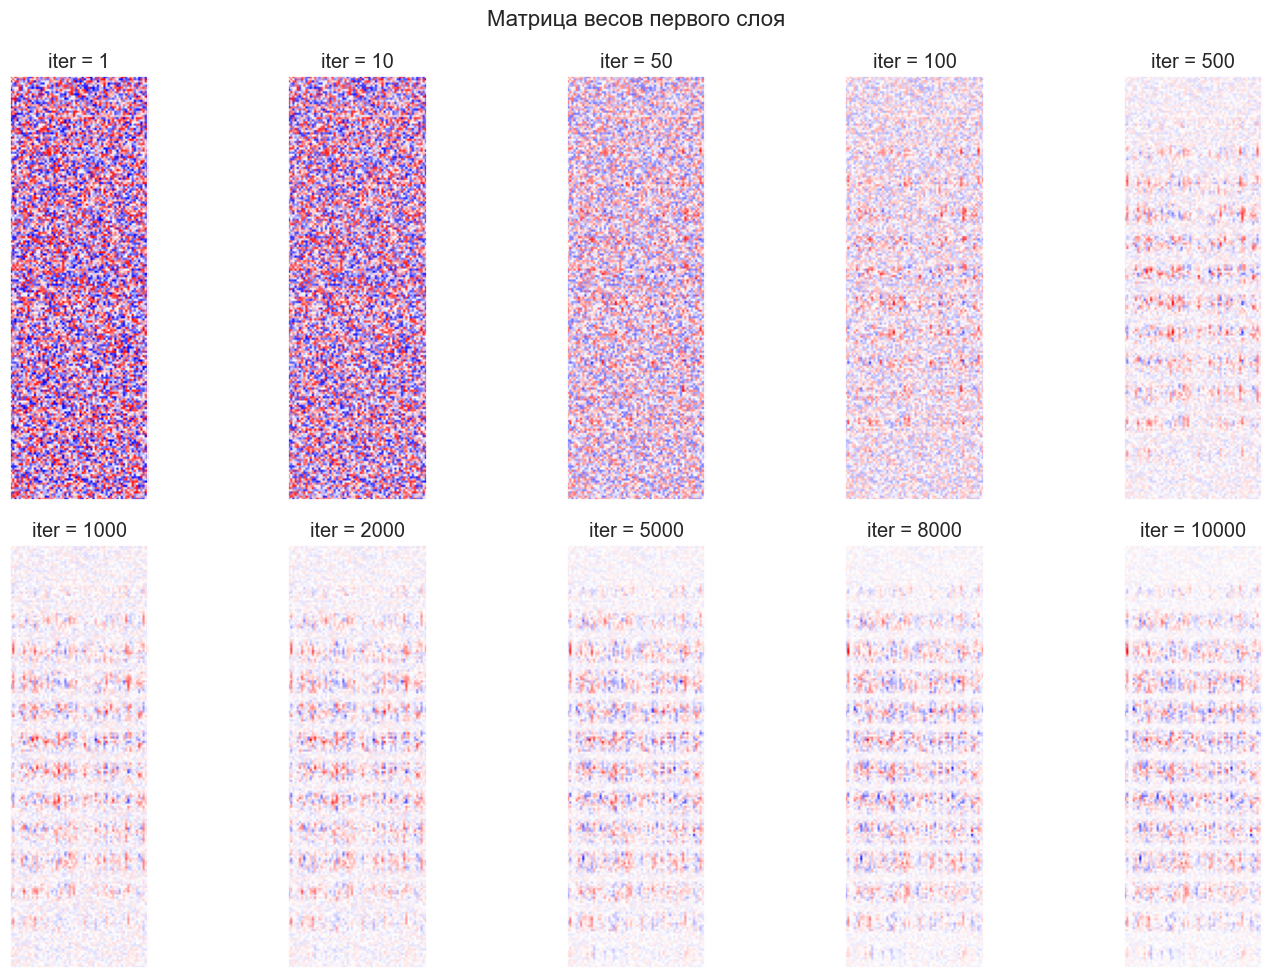

In [253]:
# Для первого слоя
plt.figure(figsize=(15, 10))
for i, iteration in enumerate(save_iters, 1):
    w1 = weights_history["layer_1"][iteration].T  # транспонируем
    vmax = np.max(np.abs(w1))
    plt.subplot(2, 5, i)
    plt.imshow(w1, cmap="bwr", vmin=-vmax, vmax=vmax)
    plt.title(f"iter = {iteration}")
    plt.xticks([])
    plt.yticks([])

plt.suptitle("Матрица весов первого слоя", fontsize=16)
plt.tight_layout()
plt.show()

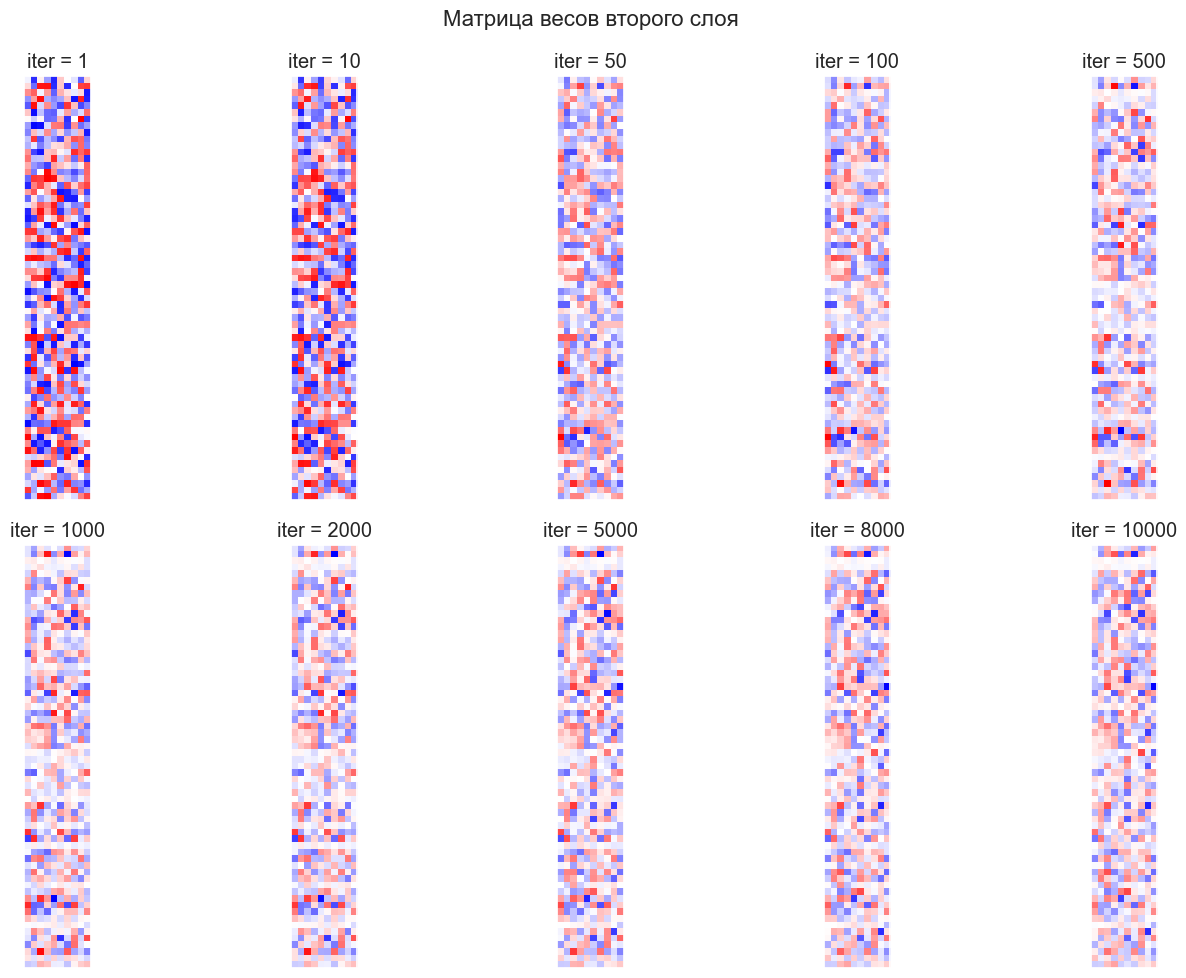

In [254]:
# Для второго слоя
plt.figure(figsize=(15, 10))
for i, iteration in enumerate(save_iters, 1):
    w2 = weights_history["layer_2"][iteration].T
    vmax = np.max(np.abs(w2))
    plt.subplot(2, 5, i)
    plt.imshow(w2, cmap="bwr", vmin=-vmax, vmax=vmax)
    plt.title(f"iter = {iteration}")
    plt.xticks([])
    plt.yticks([])

plt.suptitle("Матрица весов второго слоя", fontsize=16)
plt.tight_layout()
plt.show()

Какие выводы можно сделать, основываясь на полученных визуализациях?
Подумайте, почему на больших итерациях для первого слоя начинают выделяться определенные пиксели? Почему именно эти пиксели?

*Подсказка: вспомните, как устроены входные изображения цифр, с которыми мы работаем.*

### Ответ:

По визуализациям видно, что в начале обучения (итерации 1-10) веса распределены почти случайно, и на матрицах нет выраженной структуры.  
По мере обучения в матрице весов первого слоя начинают выделяться определённые группы пикселей.

Например, уже на итерации 500 начинают проявляться первые намёки на структуру, а к итерации 1000 становятся заметны отдельные вертикальные полосы.

К итерации 5000 структура становится отчётливой: в матрице весов первого слоя чётко выделяются области, которые соответствуют центру изображения и контурам цифр. На финальной итерации 10000 эта структура закрепляется — видно, какие именно пиксели (центральные, краевые) получают наибольшие по модулю веса.

Это происходит, потому что сеть учится находить наиболее информативные области изображения для распознавания цифр.  
Во входных изображениях MNIST цифры обычно расположены ближе к центру, а углы и края часто остаются фоновыми.  
Поэтому в процессе обучения именно центральные и контурные области изображения начинают сильнее влиять на активации нейронов первого слоя.

То есть первый слой постепенно учится выделять характерные элементы написания цифр: линии, штрихи и контуры цифр.

Во втором слое структура уже менее напрямую связана с отдельными пикселями, так как этот слой работает не с изображением, а с признаками, извлечёнными первым слоем.  
Поэтому его веса отражают комбинации найденных признаков, которые помогают различать классы.

**4.** Попробуйте **улучшить точность классификации**, рассмотрев больше нейронов в промежуточном слое.

In [255]:
model_wide = nn.Sequential(
    nn.Linear(14 * 14, 128),   # 128 нейронов в промежуточном слое
    nn.ReLU(),
    nn.Linear(128, 10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_wide.parameters(), lr=0.1)

num_iters = 10_000
log_every = 10
save_iters = [1, 10, 50, 100, 500, 1000, 2000, 5000, 8000, 10000]

loss_values_wide = []
train_accuracy_wide = []
test_accuracy_wide = []
iterations_wide = []

weights_history_wide = {
    "layer_1": {},
    "layer_2": {},
}

start_time_wide = time.time()

for iteration in range(1, num_iters + 1):
    optimizer.zero_grad()

    train_logits = model_wide(train_images)
    loss = loss_fn(train_logits, train_labels)

    loss.backward()
    optimizer.step()

    if iteration in save_iters:
        weights_history_wide["layer_1"][iteration] = model_wide[0].weight.detach().numpy().copy()
        weights_history_wide["layer_2"][iteration] = model_wide[2].weight.detach().numpy().copy()

    if iteration % log_every == 0 or iteration == 1:
        with torch.no_grad():
            train_logits = model_wide(train_images)
            test_logits = model_wide(test_images)

            train_acc = accuracy_from_logits(train_logits, train_labels)
            test_acc = accuracy_from_logits(test_logits, test_labels)

        loss_values_wide.append(loss.item())
        train_accuracy_wide.append(train_acc)
        test_accuracy_wide.append(test_acc)
        iterations_wide.append(iteration)

elapsed_time_wide = time.time() - start_time_wide

print(f"Время обучения: {elapsed_time_wide:.2f} сек ({elapsed_time_wide / 60:.2f} мин)")
print(f"Финальная train accuracy: {train_accuracy_wide[-1]:.4f}")
print(f"Финальная test accuracy: {test_accuracy_wide[-1]:.4f}")

Время обучения: 33.85 сек (0.56 мин)
Финальная train accuracy: 0.9842
Финальная test accuracy: 0.9560


Теперь попробуйте добавить к сети еще один слой.

In [256]:
model_deep = nn.Sequential(
    nn.Linear(14 * 14, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_deep.parameters(), lr=0.1)

num_iters = 10_000
log_every = 10
save_iters = [1, 10, 50, 100, 500, 1000, 2000, 5000, 8000, 10000]

loss_values_deep = []
train_accuracy_deep = []
test_accuracy_deep = []
iterations_deep = []

weights_history_deep = {
    "layer_1": {},
    "layer_2": {},
    "layer_3": {},
}

start_time_deep = time.time()

for iteration in range(1, num_iters + 1):
    optimizer.zero_grad()

    train_logits = model_deep(train_images)
    loss = loss_fn(train_logits, train_labels)

    loss.backward()
    optimizer.step()

    if iteration in save_iters:
        weights_history_deep["layer_1"][iteration] = model_deep[0].weight.detach().numpy().copy()
        weights_history_deep["layer_2"][iteration] = model_deep[2].weight.detach().numpy().copy()
        weights_history_deep["layer_3"][iteration] = model_deep[4].weight.detach().numpy().copy()

    if iteration % log_every == 0 or iteration == 1:
        with torch.no_grad():
            train_logits = model_deep(train_images)
            test_logits = model_deep(test_images)

            train_acc = accuracy_from_logits(train_logits, train_labels)
            test_acc = accuracy_from_logits(test_logits, test_labels)

        loss_values_deep.append(loss.item())
        train_accuracy_deep.append(train_acc)
        test_accuracy_deep.append(test_acc)
        iterations_deep.append(iteration)

elapsed_time_deep = time.time() - start_time_deep

print(f"Время обучения: {elapsed_time_deep:.2f} сек ({elapsed_time_deep / 60:.2f} мин)")
print(f"Финальная train accuracy: {train_accuracy_deep[-1]:.4f}")
print(f"Финальная test accuracy: {test_accuracy_deep[-1]:.4f}")

Время обучения: 49.73 сек (0.83 мин)
Финальная train accuracy: 1.0000
Финальная test accuracy: 0.9597


Насколько дольше обучается нейросеть? Получилось ли улучшить качество?

### Ответ:
1. Базовая модель (один промежуточный слой, 64 нейрона):

Время обучения: 154.52 сек (2.58 мин)

Точность на train: 98.15%

Точность на test: 95.39%

2. Широкая модель (один промежуточный слой, 128 нейронов):

Время обучения: 33.85 сек (0.56 мин) — быстрее базовой модели

Точность на train: 98.42%

Точность на test: 95.60% (+0.21% к базовой)

3. Глубокая модель (два промежуточных слоя: 128 -> 64 нейрона):

Время обучения: 49.73 сек (0.83 мин) — дольше широкой модели

Точность на train: 100.00%

Точность на test: 95.97% (+0.58% к базовой, +0.37% к широкой)


**5.** Сделайте выводы.


### Ответ:
Широкая модель показала лучшее время обучения и небольшой прирост качества. Несмотря на большее число параметров, она обучилась даже быстрее базовой, возможно, благодаря более эффективной инициализации или особенностям градиентного спуска.

Глубокая модель дала наибольший прирост точности на тесте (+0.58% к базовой), но обучалась дольше широкой на 15.88 сек. На обучающей выборке она достигла 100% точности, что говорит о её высокой выразительной способности.

В данном случае увеличение сложности модели оправдано — каждая следующая архитектура улучшала качество на тестовой выборке. Однако прирост точности нелинейный: широкий слой дал +0.21%, глубокая архитектура — ещё +0.37%.

Компромисс - если важна скорость обучения, оптимальна широкая модель (128 нейронов). Если важна максимальная точность — глубокая модель предпочтительнее, хотя обучается дольше.

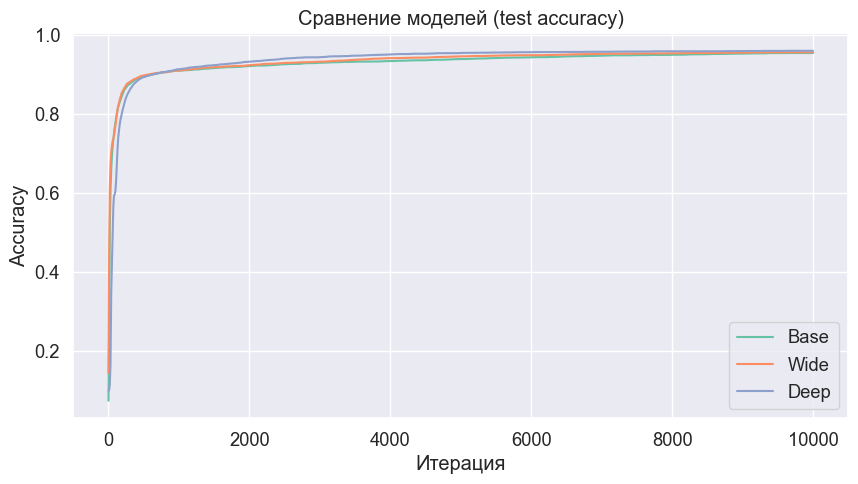

In [257]:
plt.figure(figsize=(10, 5))

plt.plot(iterations, test_accuracy, label="Base")
plt.plot(iterations_wide, test_accuracy_wide, label="Wide")
plt.plot(iterations_deep, test_accuracy_deep, label="Deep")

plt.title("Сравнение моделей (test accuracy)")
plt.xlabel("Итерация")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

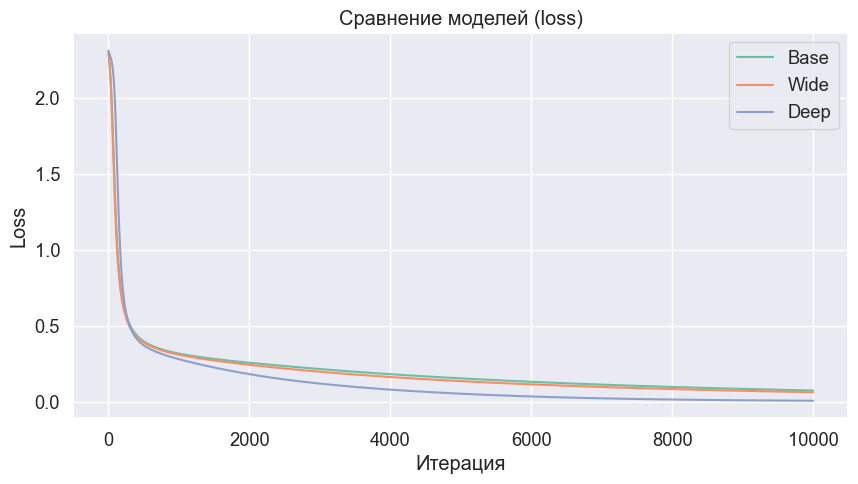

In [258]:
plt.figure(figsize=(10, 5))

plt.plot(iterations, loss_values, label="Base")
plt.plot(iterations_wide, loss_values_wide, label="Wide")
plt.plot(iterations_deep, loss_values_deep, label="Deep")

plt.title("Сравнение моделей (loss)")
plt.xlabel("Итерация")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

**Вывод:**

Для сравнения моделей были построены графики accuracy и loss.

Все три модели изображены на одном графике, что позволяет напрямую сравнить скорость сходимости и качество обучения.

Из графиков видно, что широкая и глубокая модели сходятся быстрее базовой, а глубокая модель достигает наилучшего значения accuracy.

---
### Задача 2.

**При решении задачи запрещено пользоваться ИИ-инструментами,** но можно при оформлении решения.


Рассмотрим *упрощенную* нейронную сеть с механизмом Attention, которая решает задачу анализа тональности текста. На вход сети поступает фраза, состоящая *ровно из двух слов*. Слова уже переведены в векторы (эмбеддинги) $x_1, x_2 \in \mathbb{R}^d$. Сеть должна предсказать вероятность того, что фраза имеет позитивный окрас. Для этого модель использует обучаемый вектор-запрос (Query) $q \in \mathbb{R}^d$, который «ищет», на какое из двух слов нужно обратить больше внимания.

Прямой проход нейросети выглядит следующим образом.

1. С помощью скалярного произведения оцениваем важности каждого слова:
$$z_1(x_1) = q^{\top} x_1, \quad z_2(x_2) = q^{\top} x_2$$

2. Получаем веса внимания с помощью функции Softmax:
$$\alpha_1(z_1, z_2) = \frac{e^{z_1}}{e^{z_1} + e^{z_2}}, \quad \alpha_2(z_1, z_2) = \frac{e^{z_2}}{e^{z_1} + e^{z_2}}$$

3. Формируем вектор контекста $c \in \mathbb{R}^d$ как взвешенную сумму слов:
$$c(x_1, x_2, \alpha_1, \alpha_2) = \alpha_1 x_1 + \alpha_2 x_2$$

4. Пропускаем контекст через линейный классификатор с логистической сигмоидой для получения оценки вероятности позитивного окраса фразы:
$$y_\theta(x_1, x_2) = f(c) = \sigma(w^{\top} c + b),$$
где $\theta$ &mdash; общий набор обучаемых параметров.

**1.** Нарисуйте схематически данную нейронную сеть в виде графа вычислений. Сколько у нее обучаемых параметров (размерность $\theta$)?

*Схему можно нарисовать от руки или в каком-либо редакторе. Для вставки изображения скопируйте его и вставьте в ячейку markdown с помощью `Ctrl+V`. Должно появится либо большое количество символов (Colab), либо что-то вроде `![image.png](attachment:image.png)`. Если этот способ не работает, можно загрузить картинку в коде и вывести ее в output ячейки.*

### Пункт 1

Модель состоит из механизма внимания и линейного классификатора.

1. **Механизм внимания (Attention)**

   Для входных эмбеддингов $x_1, x_2 \in \mathbb{R}^d$ вычисляются:
   $$
   z_1 = q^\top x_1,\quad z_2 = q^\top x_2.
   $$

   Затем с помощью softmax получаются веса внимания:
   $$
   \alpha_1 = \frac{e^{z_1}}{e^{z_1}+e^{z_2}},\quad
   \alpha_2 = \frac{e^{z_2}}{e^{z_1}+e^{z_2}}.
   $$

2. **Классификатор**

   Формируется вектор контекста:
   $$
   c = \alpha_1 x_1 + \alpha_2 x_2,
   $$

   после чего он подаётся в линейный классификатор:
   $$
   s = w^\top c + b,
   $$
   
   а затем через сигмоиду:
   $$
   \hat y = \sigma(s).
   $$

Обучаемые параметры сети:
- $q \in \mathbb{R}^d$,
- $w \in \mathbb{R}^d$,
- $b \in \mathbb{R}$.

Следовательно, общее число обучаемых параметров равно
$$
|\theta| = d + d + 1 = 2d + 1.
$$

### Схема

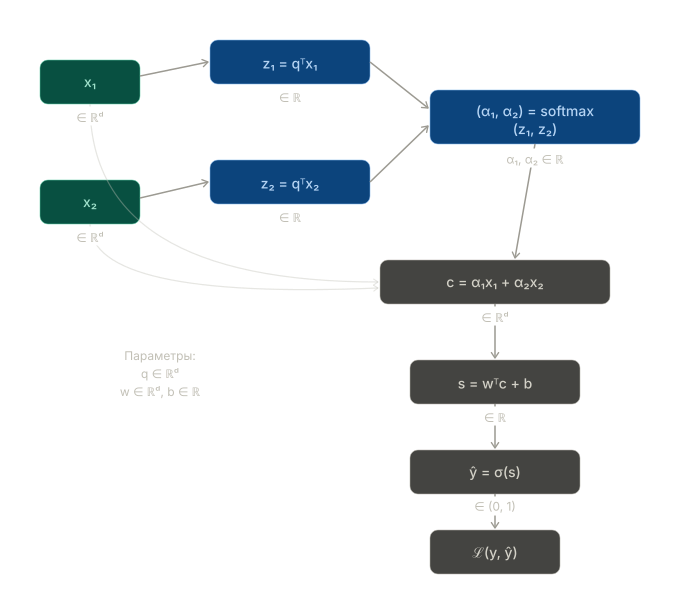

In [4]:
display(SVG('/Users/dianakurnicova/Documents/vvad_hw5/diagram.svg'))

| Шаг | Операция | Вход | Выход |
|-----|----------|------|-------|
| 1. Оценка важности слов | $z_k = q^\top x_k$ | $q, x_k \in \mathbb{R}^d$ | $z_1, z_2 \in \mathbb{R}$ |
| 2. Веса внимания (Softmax) | $\alpha_k = \frac{e^{z_k}}{e^{z_1}+e^{z_2}}$ | $z_1, z_2 \in \mathbb{R}$ | $\alpha_1, \alpha_2 \in \mathbb{R}$ |
| 3. Вектор контекста | $c = \alpha_1 x_1 + \alpha_2 x_2$ | $\alpha_1, \alpha_2 \in \mathbb{R},\ x_1, x_2 \in \mathbb{R}^d$ | $c \in \mathbb{R}^d$ |
| 4. Линейный классификатор | $s = w^\top c + b$ | $w, c \in \mathbb{R}^d,\ b \in \mathbb{R}$ | $s \in \mathbb{R}$ |
| 5. Сигмоида | $\hat y = \sigma(s)$ | $s \in \mathbb{R}$ | $\hat y \in (0, 1)$ |

**2.** Дана обучающая выборка $X \in \mathbb{R}^{n \times 2d}$ — матрица входных данных и $Y \in \{0, 1\}^{n}$ — таргет. Нейронная сеть обучается по этой выборке, минимизируя заданную функцию $\mathscr{L}$, в данном случае рассмотрим кросс энтропию
$$\mathscr{L}(\theta) = -\sum_{i=1}^n \bigg[ Y_i \log y_\theta(x_{1i}, x_{2i}) + (1-Y_i) \log \big(1-y_\theta(x_{1i}, x_{2i})\big) \bigg].$$

Наша цель — определить оптимальные параметры нашей модели, минимизируя функцию $\mathscr{L}(\theta)$ на заданном наборе данных. Мы будем решать эту задачу с помощью метода градиентного спуска, который требует вычисления производных по всем параметрам сети. Конечно, в данном случае несложно выписать все производные напрямую, с чем каждый из вас легко сможет справиться.

Однако прямое вычисление производных имеет квадратичную зависимость от количества параметров, что делает его неэффективным. Из-за этого мы не смогли бы быстро обучать глубокие нейронные сети. Хотя в данном случае речь идёт всего лишь о двух слоях, понимание работы методов на простых примерах было бы полезно.

На лекции был рассказан метод **обратного распространения ошибки (back propagation)** и показан его пример для двухслойной нейронной сети (на доске). Выпишите все необходимые производные для применения метода back propagation.

### Пункт 2

Для объекта $i$ прямой проход имеет вид:
$$
z_{i1}=q^\top x_{i1},\qquad z_{i2}=q^\top x_{i2},
$$

$$
\alpha_{i1}=\frac{e^{z_{i1}}}{e^{z_{i1}}+e^{z_{i2}}},\qquad
\alpha_{i2}=\frac{e^{z_{i2}}}{e^{z_{i1}}+e^{z_{i2}}},
$$

$$
c_i=\alpha_{i1}x_{i1}+\alpha_{i2}x_{i2},
$$

$$
s_i=w^\top c_i+b, \qquad \hat y_i=\sigma(s_i).
$$

Функция потерь:
$$
\mathscr{L}(\theta)= -\sum_{i=1}^n \Big[y_i \log \hat y_i + (1-y_i)\log(1-\hat y_i)\Big].
$$

Сначала выпишем производную функции потерь по выходу сети $\hat y_i$:

$$
\mathscr{L}_i = -\Big[y_i \log \hat y_i + (1-y_i)\log(1-\hat y_i)\Big].
$$

Тогда
$$
\frac{\partial \mathscr{L}_i}{\partial \hat y_i}
=
-\left(
\frac{y_i}{\hat y_i}
-
\frac{1-y_i}{1-\hat y_i}
\right)
=
\frac{\hat y_i - y_i}{\hat y_i(1-\hat y_i)}.
$$

Кроме того,
$$
\hat y_i = \sigma(s_i),
$$
поэтому производная сигмоиды по логиту равна
$$
\frac{\partial \hat y_i}{\partial s_i}
=
\sigma(s_i)\bigl(1-\sigma(s_i)\bigr)
=
\hat y_i(1-\hat y_i).
$$

Следовательно:
$$
\frac{\partial \mathscr{L}}{\partial s_i}
=
\frac{\partial \mathscr{L}_i}{\partial \hat y_i}
\cdot
\frac{\partial \hat y_i}{\partial s_i}
=
\frac{\hat y_i - y_i}{\hat y_i(1-\hat y_i)}
\cdot
\hat y_i(1-\hat y_i)
=
\hat y_i-y_i.
$$

Обозначим
$$
\delta_i=\hat y_i-y_i.
$$

Тогда производные по параметрам классификатора:
$$
\frac{\partial \mathscr{L}}{\partial w}=\sum_{i=1}^n \delta_i c_i,\qquad
\frac{\partial \mathscr{L}}{\partial b}=\sum_{i=1}^n \delta_i.
$$

Производная по контекстному вектору:
$$
\frac{\partial \mathscr{L}}{\partial c_i}=\delta_i w.
$$

Далее:
$$
\frac{\partial \mathscr{L}}{\partial \alpha_{i1}}
=
\left(\frac{\partial \mathscr{L}}{\partial c_i}\right)^\top x_{i1}
=
\delta_i\, w^\top x_{i1},
$$

$$
\frac{\partial \mathscr{L}}{\partial \alpha_{i2}}
=
\left(\frac{\partial \mathscr{L}}{\partial c_i}\right)^\top x_{i2}
=
\delta_i\, w^\top x_{i2}.
$$

Используя производные softmax, получаем:
$$
\frac{\partial \mathscr{L}}{\partial z_{i1}}
=
\alpha_{i1}\alpha_{i2}\left(
\frac{\partial \mathscr{L}}{\partial \alpha_{i1}}
-
\frac{\partial \mathscr{L}}{\partial \alpha_{i2}}
\right)
=
\alpha_{i1}\alpha_{i2}\,\delta_i\, w^\top(x_{i1}-x_{i2}),
$$

$$
\frac{\partial \mathscr{L}}{\partial z_{i2}}
=
\alpha_{i1}\alpha_{i2}\left(
\frac{\partial \mathscr{L}}{\partial \alpha_{i2}}
-
\frac{\partial \mathscr{L}}{\partial \alpha_{i1}}
\right)
=
\alpha_{i1}\alpha_{i2}\,\delta_i\, w^\top(x_{i2}-x_{i1}).
$$

Так как
$$
z_{i1}=q^\top x_{i1},\qquad z_{i2}=q^\top x_{i2},
$$
то
$$
\frac{\partial \mathscr{L}}{\partial q}
=
\sum_{i=1}^n
\left(
\frac{\partial \mathscr{L}}{\partial z_{i1}}x_{i1}
+
\frac{\partial \mathscr{L}}{\partial z_{i2}}x_{i2}
\right).
$$

После упрощения:
$$
\frac{\partial \mathscr{L}}{\partial q}
=
\sum_{i=1}^n
\alpha_{i1}\alpha_{i2}\,\delta_i\,
\bigl(w^\top(x_{i1}-x_{i2})\bigr)\,(x_{i1}-x_{i2}).
$$

**3.** Выпишите итоговый алгоритм обратного распространения ошибки для данной нейросети. Нужно записать все необходимые вычисления в том порядке, в котором они будут выполняться **в реализации метода**, включая все итоговые формулы производных. Не производите лишних вычислений.

Подробно поясните, почему этот алгоритм имеет линейную сложность.

### Пункт 3. Итоговый алгоритм backpropagation

#### Прямой проход
Для каждого объекта $i$ вычислить:

1. Оценки внимания:
   $$
   z_{i1}=q^\top x_{i1},\qquad z_{i2}=q^\top x_{i2}.
   $$

2. Аttention веса:
   $$
   (\alpha_{i1},\alpha_{i2})=\mathrm{softmax}(z_{i1},z_{i2}).
   $$

3. Контекст:
   $$
   c_i=\alpha_{i1}x_{i1}+\alpha_{i2}x_{i2}.
   $$

4. Логит классификатора:
   $$
   s_i=w^\top c_i+b.
   $$

5. Предсказание:
   $$
   \hat y_i=\sigma(s_i).
   $$

6. Функцию потерь:
   $$
   \mathscr{L}=-\sum_{i=1}^n \Big[y_i\log\hat y_i+(1-y_i)\log(1-\hat y_i)\Big].
   $$

#### Обратный проход
1. Ошибка на выходе:
   $$
   \delta_i=\hat y_i-y_i.
   $$

2. Градиенты по параметрам классификатора:
   $$
   \nabla_w\mathscr{L}=\sum_{i=1}^n \delta_i c_i,
   \qquad
   \nabla_b\mathscr{L}=\sum_{i=1}^n \delta_i.
   $$

3. Градиент по контексту:
   $$
   g_i=\frac{\partial \mathscr{L}}{\partial c_i}=\delta_i w.
   $$

4. Производные по attention весам:
   $$
   \beta_{i1}=g_i^\top x_{i1},
   \qquad
   \beta_{i2}=g_i^\top x_{i2}.
   $$
5. Производные по входам softmax:
   $$
   \gamma_i=\alpha_{i1}\alpha_{i2}(\beta_{i1}-\beta_{i2}),
   $$
   $$
   \frac{\partial \mathscr{L}}{\partial z_{i1}}=\gamma_i,
   \qquad
   \frac{\partial \mathscr{L}}{\partial z_{i2}}=-\gamma_i.
   $$

6. Градиент по вектору запроса:
   $$
   \nabla_q\mathscr{L}=\sum_{i=1}^n \gamma_i(x_{i1}-x_{i2}).
   $$

Итоговые градиенты:
$$
\nabla_\theta \mathscr{L} = \left(\nabla_q\mathscr{L},\ \nabla_w\mathscr{L},\ \nabla_b\mathscr{L}\right).
$$

**Выводы:**

### Почему алгоритм имеет линейную сложность

Алгоритм имеет линейную сложность по числу объектов и размерности эмбеддингов.

Для каждого объекта выполняется фиксированное число операций с векторами длины $d$:

- два скалярных произведения $q^\top x_{i1}$ и $q^\top x_{i2}$,
- вычисление softmax по двум значениям,
- одна взвешенная сумма векторов для получения контекста $c_i$,
- одно скалярное произведение $w^\top c_i$,
- а на обратном проходе — аналогичные операции той же размерности.

Следовательно, стоимость обработки одного объекта равна $O(d)$, а всей выборки из $n$ объектов — $O(nd)$.

Число обучаемых параметров в модели равно $2d+1$, поэтому сложность также линейна по числу параметров.

Метод backpropagation эффективен, потому что он повторно использует промежуточные результаты прямого прохода и не вычисляет производные независимо друг от друга с нуля.

**Внимание!** Решение, которое будет иметь сверхлинейную сложность, не будет оценено совсем. Считать производные вы все умеете, задача — вычислять их эффективно алгоритмически.

---

### Задача 3.

Рассмотрим глубокую нейронную сеть, которая
* принимает на вход $x\in\mathbb{R}^d$,
* возвращает логиты,
* содержит $100$ полносвязных слоев (`Linear`) с функцией активации $\tanh$, за исключением последнего слоя.

В качестве лосса $\mathscr{L}(\theta)$ возьмем кросс-энтропию `torch.nn.BCEWithLogitsLoss`

*Примечание.* Альтернативный способ &mdash; для последнего слоя использовать функцию активации логистическая сигмоида, возвращая тем самым оценки вероятностей, и далее применять `torch.nn.BCELoss`. Однако, способ с использованием логитов является численно более устойчивым.

**1.** Распишите градиент лосса по весам первого слоя $W_1$. Какова сложность этой операции?

### Пункт 1

Обозначим через $h_l$ предактивацию $l$-го слоя, а через $a_l$ — его активацию:
$$
h_1 = W_1x + b_1, \qquad a_1 = \tanh(h_1),
$$
$$
h_l = W_l a_{l-1} + b_l, \qquad a_l = \tanh(h_l), \qquad l=2,\dots,99.
$$

Последний слой линейный и возвращает логит:
$$
z = W_{100}a_{99} + b_{100}.
$$

Функция потерь:
$$
\mathscr{L}(z,y)=\mathrm{BCEWithLogitsLoss}(z,y).
$$

Для BCEWithLogitsLoss производная по логиту имеет вид:
$$
\frac{\partial \mathscr{L}}{\partial z}=\sigma(z)-y.
$$

Обозначим
$$
\delta_{100}=\frac{\partial \mathscr{L}}{\partial z}=\sigma(z)-y.
$$

Для промежуточных слоёв backpropagation даёт рекуррентную формулу:
$$
\delta_l
=
\frac{\partial \mathscr{L}}{\partial h_l}
=
\left(W_{l+1}^\top \delta_{l+1}\right)\odot\left(1-\tanh^2(h_l)\right),
\qquad l=99,\dots,1.
$$

Для первого слоя:
$$
\delta_1
=
\left(W_2^\top \delta_2\right)\odot\left(1-\tanh^2(h_1)\right).
$$

Так как
$$
h_1=W_1x+b_1,
$$
то градиент по весам первого слоя для одного объекта равен
$$
\frac{\partial \mathscr{L}}{\partial W_1}=\delta_1 x^\top.
$$

Если рассматривать батч из $n$ объектов, то
$$
\frac{\partial \mathscr{L}}{\partial W_1}
=
\sum_{i=1}^n \delta_1^{(i)} (x^{(i)})^\top.
$$

Или в матричном виде
$$
\frac{\partial \mathscr{L}}{\partial W_1}=\Delta_1^\top X.
$$

Сама операция вычисления градиента
$$
\frac{\partial \mathscr{L}}{\partial W_1}=\delta_1 x^\top
$$
представляет собой внешнее произведение векторов и для одного объекта имеет сложность $O(hd)$, где $d$ — размер входа, а $h$ — число нейронов первого слоя.

Для батча из $n$ объектов сложность равна $$O(nhd).$$

При этом для получения $\delta_1$ нужно сначала провести ошибку назад через все последующие слои. Поэтому основная идея состоит в том, что производные считаются последовательно от последнего слоя к первому методом backpropagation.

Заметим, что для вычисления $\delta_1$ нужно последовательно вычислить
$$
\delta_{100}, \delta_{99}, \dots, \delta_2, \delta_1,
$$
то есть выполнить обратное распространение ошибки через все слои сети.

Если сеть содержит $L$ слоёв, то число таких шагов пропорционально $L$.

Следовательно, сложность вычисления градиента по весам первого слоя линейно зависит от числа слоёв сети:
$$
O(L).
$$

Итоговая сложность вычисления градиента по весам первого слоя для батча из $n$ объектов составляет
$$
O(nhd + L),
$$
где первый член соответствует вычислению самого градиента, а второй — распространению ошибки через слои сети.

Нарисуйте график функции активации и ее производной.

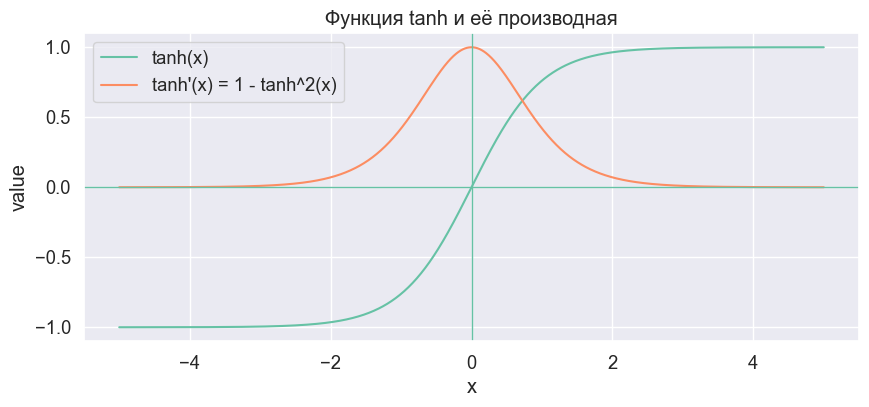

In [260]:
x = np.linspace(-5, 5, 1000)
y = np.tanh(x)
dy = 1 - y**2

plt.figure(figsize=(10, 4))
plt.plot(x, y, label="tanh(x)")
plt.plot(x, dy, label="tanh'(x) = 1 - tanh^2(x)")
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.title("Функция tanh и её производная")
plt.xlabel("x")
plt.ylabel("value")
plt.legend()
plt.grid(True)
plt.show()

На основе графика проанализируйте, что будет происходить с градиентом по весам первого слоя, если нейросеть "ненулевая", иначе говоря, на промежуточных слоях может выдавать различные значения, в том числе довольно большие.

### Анализ графика функции активации

Для функции активации
$$
\tanh(x)
$$
производная равна
$$
\tanh'(x)=1-\tanh^2(x).
$$

Из графика видно, что:
- вблизи нуля производная близка к 1;
- при больших по модулю значениях аргумента функция $\tanh(x)$ насыщается и стремится к $\pm 1$;
- в области насыщения её производная становится близкой к нулю.

Это означает, что если на промежуточных слоях предактивации имеют большие по модулю значения, то множители
$$
1-\tanh^2(h_l)
$$
в формуле backpropagation будут малы.

Поскольку градиент первого слоя получается как произведение большого числа матриц и производных активации по цепочке, его норма может очень быстро уменьшаться. Следовательно, в глубокой сети с активацией `tanh` возникает проблема **затухания градиента**: градиент по весам первых слоёв становится очень маленьким, и эти слои обучаются плохо.

**2.** Реализуйте эту нейросеть на **PyTorch**.

*Примечание.* Каждый слой должен быть инициализирован отдельно. Нельзя создавать копии уже инициализированного слоя. Можно использовать `nn.Sequential`.

In [261]:
# Оставим только классы 0 и 1, так как используется BCEWithLogitsLoss
train_mask = (train_labels == 0) | (train_labels == 1)
test_mask = (test_labels == 0) | (test_labels == 1)

x_train = train_images[train_mask]
y_train = train_labels[train_mask].float()

x_test = test_images[test_mask]
y_test = test_labels[test_mask].float()

print("Train:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)
print("Train classes:", torch.unique(y_train))
print("Test classes:", torch.unique(y_test))

Train: torch.Size([2080, 196]) torch.Size([2080])
Test: torch.Size([2115, 196]) torch.Size([2115])
Train classes: tensor([0., 1.])
Test classes: tensor([0., 1.])


Обучите эту нейросеть для классификации изображений **с цифрами 0 и 1** из датасета MNIST с картинками размера **14x14**. Возможно, большой батч не поместится в память, поэтому предлагается использовать случайную подвыборку (батч) размера 32 на каждом шаге обучения:
```
idx = np.random.choice(len(x_train), 32)
x_batch = x_train[idx]
```

Визуализируйте лоссы и метрики во время обучения также как в задаче 1, на обучающей и тестовой выборках.

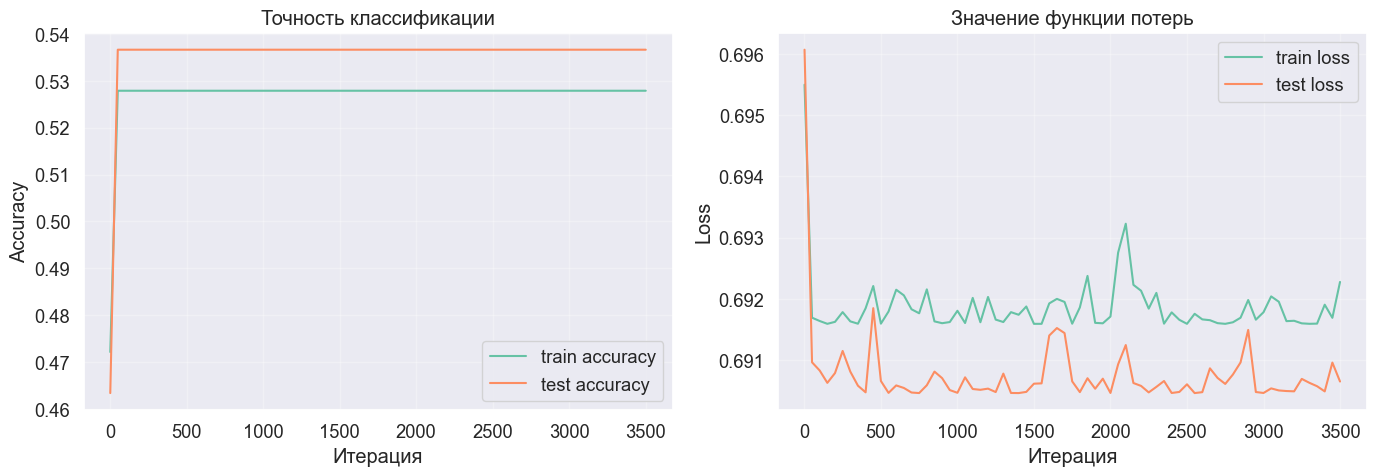

Итерация: 3500
Train loss: 0.6923
Test loss: 0.6906
Train accuracy: 0.5279
Test accuracy: 0.5366
Время обучения: 31.13 сек (0.52 мин)
Финальная train accuracy: 0.5279
Финальная test accuracy: 0.5366


In [262]:
def binary_accuracy_from_logits(logits, labels):
    if logits.dim() > 1 and logits.shape[1] == 1:
        logits = logits.squeeze(1)
    preds = (torch.sigmoid(logits) >= 0.5).float()
    return (preds == labels).float().mean().item()


layers = []
layers.append(nn.Linear(14 * 14, 64))
layers.append(nn.Tanh())

for _ in range(98):
    layers.append(nn.Linear(64, 64))
    layers.append(nn.Tanh())

layers.append(nn.Linear(64, 1))

model_deep_tanh = nn.Sequential(*layers)  # распаковываем список в Sequential
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_deep_tanh.parameters(), lr=0.05)

num_iters = 3500
batch_size = 32
log_every = 50

loss_values_train_deep_tanh = []
loss_values_test_deep_tanh = []
train_accuracy_deep_tanh = []
test_accuracy_deep_tanh = []
iterations_deep_tanh = []

start_time_deep_tanh = time.time()

for iteration in range(1, num_iters + 1):
    model_deep_tanh.train()

    batch_indices = np.random.choice(len(x_train), batch_size, replace=True)
    x_batch = x_train[batch_indices]
    y_batch = y_train[batch_indices].float()

    optimizer.zero_grad()

    train_logits = model_deep_tanh(x_batch).squeeze(1)
    loss = loss_fn(train_logits, y_batch)

    loss.backward()
    optimizer.step()

    if iteration % log_every == 0 or iteration == 1:
        model_deep_tanh.eval()

        with torch.no_grad():
            train_logits_full = model_deep_tanh(x_train).squeeze(1)
            test_logits_full = model_deep_tanh(x_test).squeeze(1)

            train_loss = loss_fn(train_logits_full, y_train).item()
            test_loss = loss_fn(test_logits_full, y_test).item()

            train_acc = binary_accuracy_from_logits(train_logits_full, y_train)
            test_acc = binary_accuracy_from_logits(test_logits_full, y_test)

        loss_values_train_deep_tanh.append(train_loss)
        loss_values_test_deep_tanh.append(test_loss)
        train_accuracy_deep_tanh.append(train_acc)
        test_accuracy_deep_tanh.append(test_acc)
        iterations_deep_tanh.append(iteration)

        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].plot(iterations_deep_tanh, train_accuracy_deep_tanh, label="train accuracy")
        axes[0].plot(iterations_deep_tanh, test_accuracy_deep_tanh, label="test accuracy")
        axes[0].set_title("Точность классификации")
        axes[0].set_xlabel("Итерация")
        axes[0].set_ylabel("Accuracy")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        axes[1].plot(iterations_deep_tanh, loss_values_train_deep_tanh, label="train loss")
        axes[1].plot(iterations_deep_tanh, loss_values_test_deep_tanh, label="test loss")
        axes[1].set_title("Значение функции потерь")
        axes[1].set_xlabel("Итерация")
        axes[1].set_ylabel("Loss")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

        print(f"Итерация: {iteration}")
        print(f"Train loss: {train_loss:.4f}")
        print(f"Test loss: {test_loss:.4f}")
        print(f"Train accuracy: {train_acc:.4f}")
        print(f"Test accuracy: {test_acc:.4f}")

elapsed_time_deep_tanh = time.time() - start_time_deep_tanh

print(f"Время обучения: {elapsed_time_deep_tanh:.2f} сек ({elapsed_time_deep_tanh / 60:.2f} мин)")
print(f"Финальная train accuracy: {train_accuracy_deep_tanh[-1]:.4f}")
print(f"Финальная test accuracy: {test_accuracy_deep_tanh[-1]:.4f}")

**Вывод:**
На графике показана зависимость accuracy и loss от номера итерации для глубокой сети.

Видно, что точность остаётся на уровне около 0.53, а значение функции потерь — около 0.69 и практически не изменяется в процессе обучения.

Это означает, что модель не обучается и ведёт себя близко к случайному угадыванию.

Причина такого поведения — проблема затухания градиента в глубокой сети с функцией активации tanh.

Постройте график зависимости среднего и максимального абсолютного значения градиента по весам для каждого слоя от номера слоя.

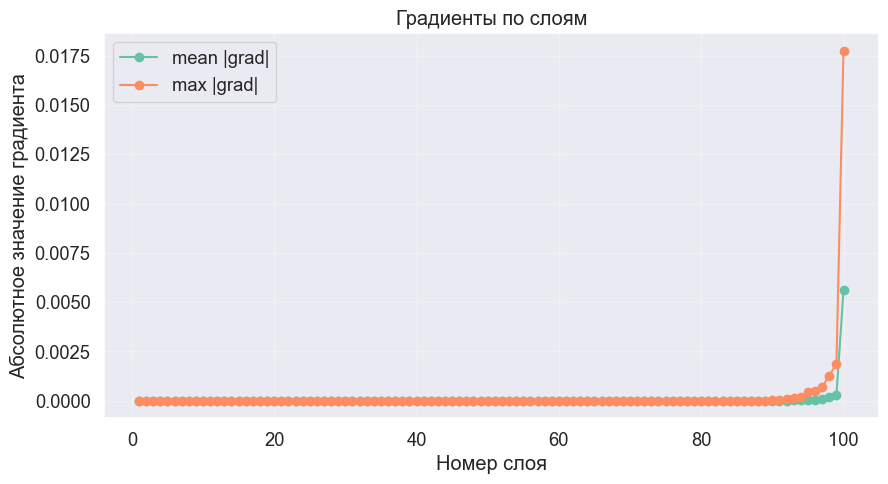

In [270]:
mean_grad_values = []
max_grad_values = []
layer_numbers = []

layer_number = 1

for layer in model_deep_tanh:
    if isinstance(layer, nn.Linear):
        grad = layer.weight.grad.detach().abs()

        mean_grad_values.append(grad.mean().item())
        max_grad_values.append(grad.max().item())
        layer_numbers.append(layer_number)

        layer_number += 1

plt.figure(figsize=(10, 5))
plt.plot(layer_numbers, mean_grad_values, marker="o", label="mean |grad|")
plt.plot(layer_numbers, max_grad_values, marker="o", label="max |grad|")

plt.title("Градиенты по слоям")
plt.xlabel("Номер слоя")
plt.ylabel("Абсолютное значение градиента")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Вывод:** На графике показаны средние и максимальные значения градиента по слоям.

Видно, что для первых слоев значения градиента близки к нулю, а заметные значения появляются только в последних слоях.

Это подтверждает проблему затухания градиента: при распространении ошибки назад по сети градиент быстро уменьшается и практически не доходит до начальных слоев.

В результате первые слои обучаются очень слабо.


На таком же датасете с обучите двухслойную нейронную сеть. Для консистентности также используйте батч размера 32. Визуализируйте лоссы и метрики во время обучения. Сравните результаты.

In [271]:
model_two_layer_tanh = nn.Sequential(
    nn.Linear(14 * 14, 64),
    nn.Tanh(),
    nn.Linear(64, 1)
)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_two_layer_tanh.parameters(), lr=0.05)

num_iters = 3500
batch_size = 32
log_every = 50

loss_values_train_two_layer = []
loss_values_test_two_layer = []
train_accuracy_two_layer = []
test_accuracy_two_layer = []
iterations_two_layer = []

start_time_two_layer = time.time()

for iteration in range(1, num_iters + 1):
    model_two_layer_tanh.train()

    batch_indices = np.random.choice(len(x_train), batch_size, replace=True)
    x_batch = x_train[batch_indices]
    y_batch = y_train[batch_indices]

    optimizer.zero_grad()

    train_logits = model_two_layer_tanh(x_batch).squeeze(1)
    loss = loss_fn(train_logits, y_batch)

    loss.backward()
    optimizer.step()

    if iteration % log_every == 0 or iteration == 1:
        model_two_layer_tanh.eval()

        with torch.no_grad():
            train_logits_full = model_two_layer_tanh(x_train).squeeze(1)
            test_logits_full = model_two_layer_tanh(x_test).squeeze(1)

            train_loss = loss_fn(train_logits_full, y_train).item()
            test_loss = loss_fn(test_logits_full, y_test).item()

            train_acc = binary_accuracy_from_logits(train_logits_full, y_train)
            test_acc = binary_accuracy_from_logits(test_logits_full, y_test)

        loss_values_train_two_layer.append(train_loss)
        loss_values_test_two_layer.append(test_loss)
        train_accuracy_two_layer.append(train_acc)
        test_accuracy_two_layer.append(test_acc)
        iterations_two_layer.append(iteration)

elapsed_time_two_layer = time.time() - start_time_two_layer

print(f"Время обучения: {elapsed_time_two_layer:.2f} сек ({elapsed_time_two_layer / 60:.2f} мин)")
print(f"Финальная train accuracy: {train_accuracy_two_layer[-1]:.4f}")
print(f"Финальная test accuracy: {test_accuracy_two_layer[-1]:.4f}")

Время обучения: 1.02 сек (0.02 мин)
Финальная train accuracy: 0.9990
Финальная test accuracy: 0.9986


### Выводы

В этой задаче была исследована глубокая полносвязная сеть с 100 промежуточными слоями и функцией активации `tanh`.

По результатам эксперимента видно, что глубокая сеть практически не обучается: значение функции потерь остаётся около 0.69, а точность — около 0.53, что близко к случайному угадыванию. Это подтверждается графиками, где метрики почти не меняются в процессе обучения.

Анализ градиентов показывает, что в первых слоях их значения близки к нулю, а заметные значения появляются только в последних слоях. Это свидетельствует о проблеме затухания градиента. При обратном распространении ошибки градиент многократно умножается на производную функции активации `tanh`, которая меньше 1, поэтому его значение быстро уменьшается по мере прохождения к начальным слоям.

В отличие от глубокой сети, двухслойная нейронная сеть успешно обучается: достигается высокая точность (около 0.99), а функция потерь уменьшается. Это согласуется с теорией, согласно которой двухслойной сети достаточно для приближения сложных функций.

Таким образом, слишком большая глубина сети без специальных приёмов (например, других функций активации) может ухудшать обучение из-за затухания градиента.

*Примечание.* Подобная ситуация известна как "паралич" нейросети. Именно поэтому такие функции активации, как ReLU, стали очень популярными. Для преодоления этого паралича существует множество методов, многие из которых мы рассмотрим на следующей лекции.

---
© 2026 команда <a href="https://thetahat.ru/">ThetaHat</a> для ВвАД